In [1]:
!pip install -q tensorflow-datasets opencv-python-headless

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay

print("Libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

Libraries imported successfully!
TensorFlow Version: 2.21.0


In [3]:
PROJECT_NAME = "Handwritten Digit and Character Recognition System"

IMAGE_SIZE = 28
NUM_DIGITS = 10
NUM_LETTERS = 26
TOTAL_CLASSES = 36

CLASS_NAMES = (
    [str(i) for i in range(10)] +
    [chr(i) for i in range(ord('A'), ord('Z') + 1)]
)

print("Project:", PROJECT_NAME)
print("Total Classes:", TOTAL_CLASSES)
print("Classes:", CLASS_NAMES)

Project: Handwritten Digit and Character Recognition System
Total Classes: 36
Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


In [5]:
(x_digit_train, y_digit_train), (x_digit_test, y_digit_test) = keras.datasets.mnist.load_data()

print("Training Data:", x_digit_train.shape)
print("Testing Data:", x_digit_test.shape)

Training Data: (60000, 28, 28)
Testing Data: (10000, 28, 28)


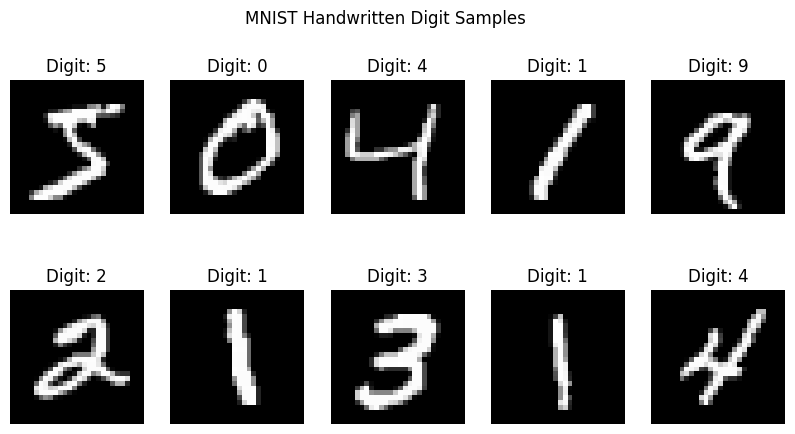

In [6]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_digit_train[i], cmap='gray')
    plt.title("Digit: " + str(y_digit_train[i]))
    plt.axis('off')

plt.suptitle("MNIST Handwritten Digit Samples")
plt.show()

In [13]:

# Load EMNIST Letters dataset

train_data, test_data = tfds.load(
    'emnist/letters',
    split=['train', 'test'],
    as_supervised=True
)

# Convert training data into NumPy arrays
train_images = []
train_labels = []

for image, label in tfds.as_numpy(train_data):
    train_images.append(image)
    train_labels.append(label)

x_letter_train = np.array(train_images)
y_letter_train = np.array(train_labels)

# Convert testing data into NumPy arrays
test_images = []
test_labels = []

for image, label in tfds.as_numpy(test_data):
    test_images.append(image)
    test_labels.append(label)

x_letter_test = np.array(test_images)
y_letter_test = np.array(test_labels)

print("Training images shape:", x_letter_train.shape)
print("Training labels shape:", y_letter_train.shape)
print("Testing images shape:", x_letter_test.shape)
print("Testing labels shape:", y_letter_test.shape)


Training images shape: (88800, 28, 28, 1)
Training labels shape: (88800,)
Testing images shape: (14800, 28, 28, 1)
Testing labels shape: (14800,)


In [14]:
def correct_orientation(images):
    return np.rot90(
        np.fliplr(images),
        k=3,
        axes=(1, 2)
    ).copy()

x_letter_train = correct_orientation(x_letter_train)
x_letter_test = correct_orientation(x_letter_test)

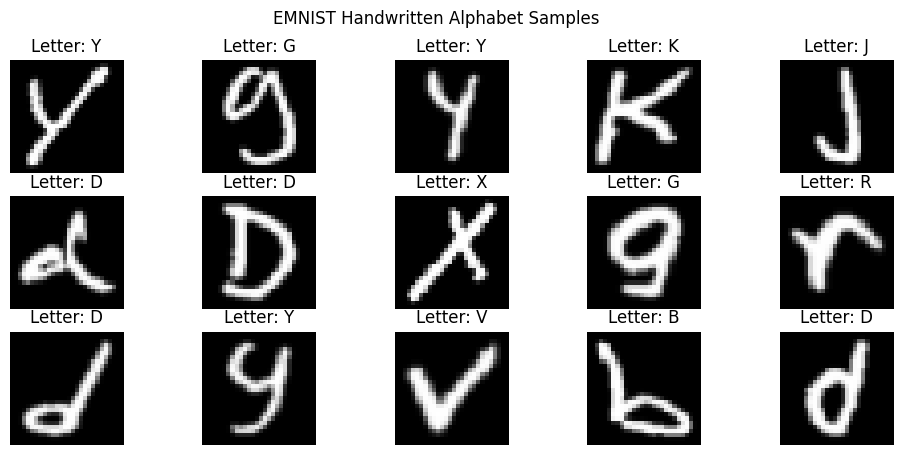

In [15]:
plt.figure(figsize=(12, 5))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(x_letter_train[i], cmap='gray')

    letter = chr(ord('A') + int(y_letter_train[i]) - 1)

    plt.title("Letter: " + letter)
    plt.axis('off')

plt.suptitle("EMNIST Handwritten Alphabet Samples")
plt.show()

In [17]:
def make_white_strokes_on_black(images):
    # If the images have a channel dimension (shape [N, 28, 28, 1]), squeeze it
    if images.ndim == 4 and images.shape[-1] == 1:
        images = images.squeeze(-1)

    images = images.copy()

    corners = np.stack([
        images[:, 0, 0],
        images[:, 0, -1],
        images[:, -1, 0],
        images[:, -1, -1]
    ], axis=1)

    background_is_bright = np.mean(corners, axis=1) > 127

    images[background_is_bright] = (
        255 - images[background_is_bright]
    )

    return images

x_letter_train = make_white_strokes_on_black(x_letter_train)
x_letter_test = make_white_strokes_on_black(x_letter_test)

print("EMNIST preprocessing completed! Shape:", x_letter_train.shape)

EMNIST preprocessing completed! Shape: (88800, 28, 28)


In [18]:
# Convert letter labels from 1-26 to 10-35

y_letter_train = y_letter_train.astype(np.int64) + 9
y_letter_test = y_letter_test.astype(np.int64) + 9

# Combine datasets

x_train = np.concatenate(
    [x_digit_train, x_letter_train],
    axis=0
)

y_train = np.concatenate(
    [y_digit_train, y_letter_train],
    axis=0
)

x_test = np.concatenate(
    [x_digit_test, x_letter_test],
    axis=0
)

y_test = np.concatenate(
    [y_digit_test, y_letter_test],
    axis=0
)

print("Combined Training Images:", x_train.shape)
print("Combined Testing Images:", x_test.shape)

Combined Training Images: (148800, 28, 28)
Combined Testing Images: (24800, 28, 28)


In [19]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Normalization completed!")

Normalization completed!


In [20]:
indices = np.random.permutation(len(x_train))

x_train = x_train[indices]
y_train = y_train[indices]

print("Dataset shuffled successfully!")

Dataset shuffled successfully!


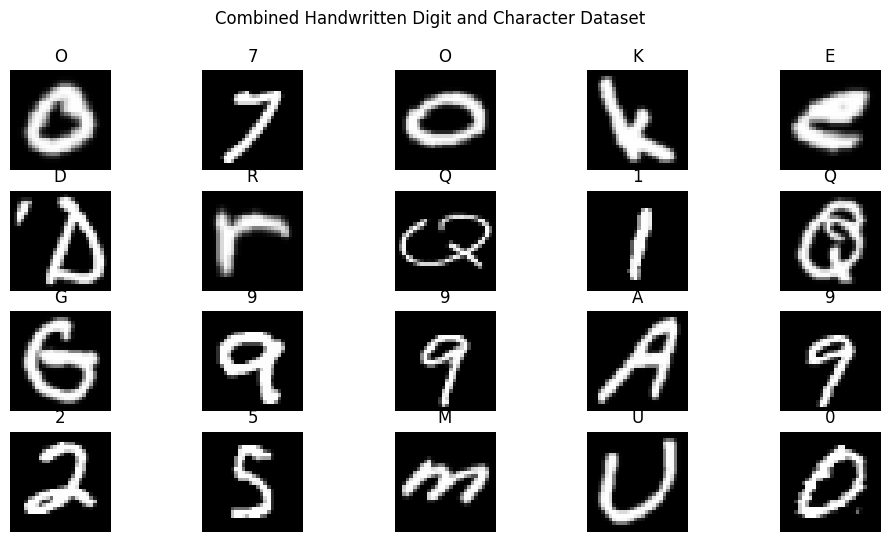

In [21]:
plt.figure(figsize=(12, 6))

for i in range(20):
    plt.subplot(4, 5, i + 1)

    plt.imshow(x_train[i].squeeze(), cmap='gray')

    plt.title(CLASS_NAMES[int(y_train[i])])
    plt.axis('off')

plt.suptitle("Combined Handwritten Digit and Character Dataset")
plt.show()

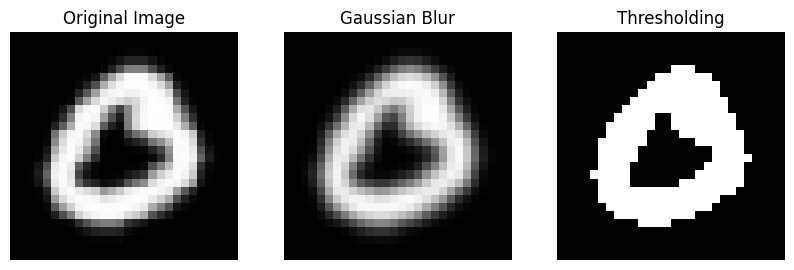

In [22]:
sample_image = (x_train[0].squeeze() * 255).astype('uint8')

blurred = cv2.GaussianBlur(sample_image, (3, 3), 0)

_, thresholded = cv2.threshold(
    blurred,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
plt.imshow(sample_image, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(blurred, cmap='gray')
plt.title("Gaussian Blur")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(thresholded, cmap='gray')
plt.title("Thresholding")
plt.axis('off')

plt.show()

In [23]:
model = keras.Sequential([

    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation='relu'),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.3),

    layers.Dense(36, activation='softmax')

])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         4,644 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 228,388 (892.14 KB)

 Trainable params: 228,388 (892.14 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
model.compile(

    optimizer='adam',

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']

)

print("CNN Model Compiled Successfully!")

CNN Model Compiled Successfully!


In [25]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2
)

history = model.fit(

    x_train,
    y_train,

    epochs=10,

    batch_size=128,

    validation_split=0.1,

    callbacks=[early_stopping, reduce_lr]

)

Epoch 1/10
1047/1047 ━━━━━━━━━━━━━━━━━━━━ 127s 119ms/step - accuracy: 0.7955 - loss: 0.6871 - val_accuracy: 0.9106 - val_loss: 0.2769 - learning_rate: 0.0010
Epoch 2/10
1047/1047 ━━━━━━━━━━━━━━━━━━━━ 132s 126ms/step - accuracy: 0.9041 - loss: 0.3067 - val_accuracy: 0.9382 - val_loss: 0.1923 - learning_rate: 0.0010
Epoch 3/10
1047/1047 ━━━━━━━━━━━━━━━━━━━━ 133s 117ms/step - accuracy: 0.9230 - loss: 0.2436 - val_accuracy: 0.9457 - val_loss: 0.1669 - learning_rate: 0.0010
Epoch 4/10
1047/1047 ━━━━━━━━━━━━━━━━━━━━ 108s 103ms/step - accuracy: 0.9319 - loss: 0.2107 - val_accuracy: 0.9505 - val_loss: 0.1528 - learning_rate: 0.0010
Epoch 5/10
1047/1047 ━━━━━━━━━━━━━━━━━━━━ 125s 119ms/step - accuracy: 0.9390 - loss: 0.1869 - val_accuracy: 0.9532 - val_loss: 0.1444 - learning_rate: 0.0010
Epoch 6/10
1047/1047 ━━━━━━━━━━━━━━━━━━━━ 141s 118ms/step - accuracy: 0.9433 - loss: 0.1713 - val_accuracy: 0.9521 - val_loss: 0.1412 - learning_rate: 0.0010
Epoch 7/10
1047/1047 ━━━━━━━━━━━━━━━━━━━━ 136s 113ms

In [26]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test
)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

775/775 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9496 - loss: 0.1504
Test Accuracy: 94.96371150016785 %
Test Loss: 0.15040206909179688


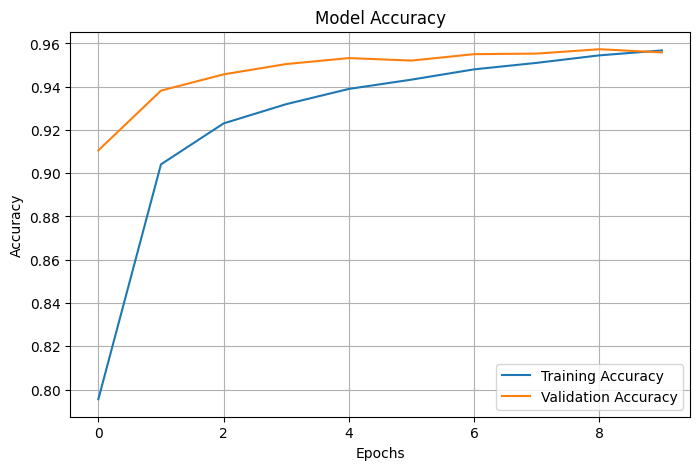

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Model Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.grid()

plt.show()

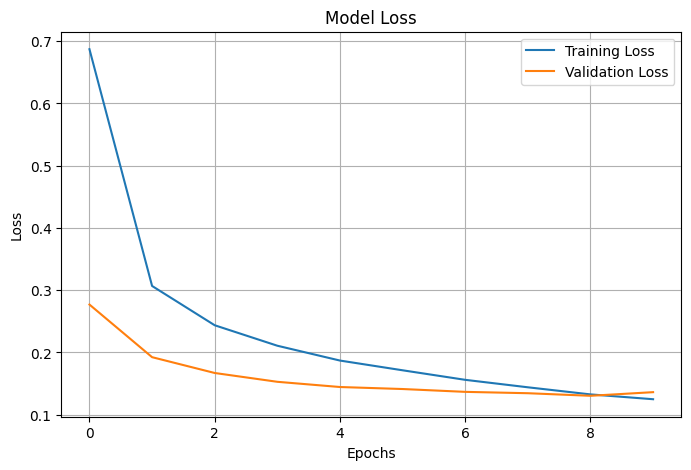

In [28]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Model Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.grid()

plt.show()

In [29]:
y_pred_prob = model.predict(x_test, batch_size=128)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Predictions generated successfully!")

194/194 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step
Predictions generated successfully!


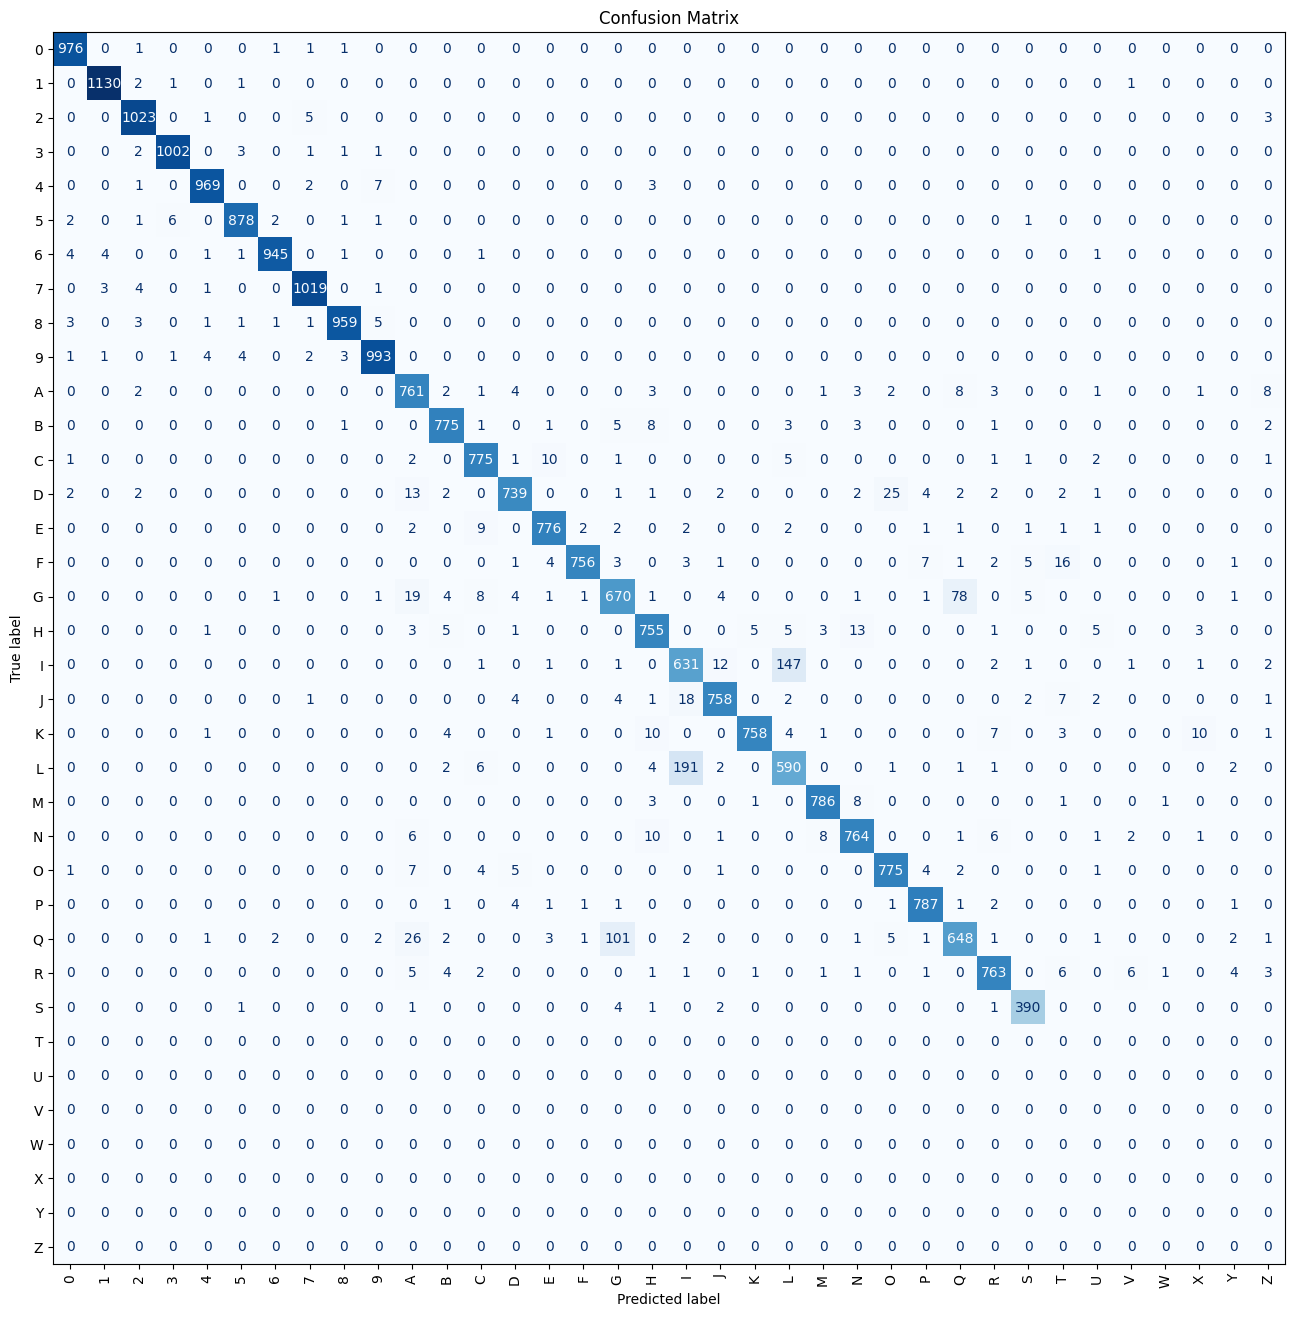

In [30]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(36)
)

fig, ax = plt.subplots(figsize=(16, 16))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot(
    ax=ax,
    cmap='Blues',
    xticks_rotation='vertical',
    colorbar=False
)

plt.title("Confusion Matrix")
plt.show()

In [31]:
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(36),
    target_names=CLASS_NAMES,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.98      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.98      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.98      0.99       974
           9       0.98      0.98      0.98      1009
           A       0.90      0.95      0.93       800
           B       0.97      0.97      0.97       800
           C       0.96      0.97      0.96       800
           D       0.97      0.92      0.95       800
           E       0.97      0.97      0.97       800
           F       0.99      0.94      0.97       800
           G       0.84      0.84      0.84       800
           H       0.94    

In [32]:
def preprocess_uploaded_image(image_path):

    image = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise ValueError("Unable to load image.")

    _, threshold = cv2.threshold(
        image,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    coords = cv2.findNonZero(threshold)

    if coords is None:
        raise ValueError("No character detected.")

    x, y, w, h = cv2.boundingRect(coords)

    cropped = threshold[y:y+h, x:x+w]

    scale = 20 / max(w, h)

    new_w = max(1, int(w * scale))
    new_h = max(1, int(h * scale))

    resized = cv2.resize(
        cropped,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    canvas = np.zeros((28, 28), dtype=np.uint8)

    x_offset = (28 - new_w) // 2
    y_offset = (28 - new_h) // 2

    canvas[
        y_offset:y_offset+new_h,
        x_offset:x_offset+new_w
    ] = resized

    processed = canvas.astype('float32') / 255.0

    processed = processed.reshape(1, 28, 28, 1)

    return processed, canvas

Saving images (8).png to images (8).png


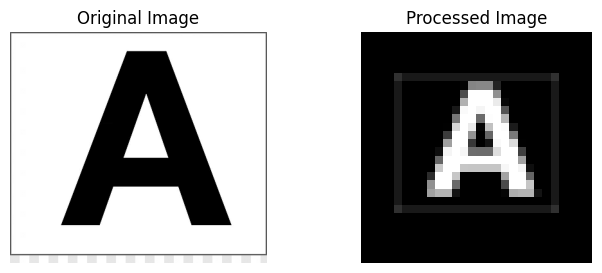

Predicted Character: 4
Confidence: 29.28 %


In [33]:
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

processed_image, display_image = preprocess_uploaded_image(image_path)

prediction = model.predict(processed_image, verbose=0)

predicted_index = np.argmax(prediction)

predicted_character = CLASS_NAMES[predicted_index]

confidence = np.max(prediction) * 100

plt.figure(figsize=(8, 3))

plt.subplot(1, 2, 1)
original = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
plt.imshow(original, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(display_image, cmap='gray')
plt.title("Processed Image")
plt.axis('off')

plt.show()

print("Predicted Character:", predicted_character)
print("Confidence:", round(confidence, 2), "%")

In [34]:
top_indices = np.argsort(prediction[0])[-5:][::-1]

print("Top 5 Predictions:")

for index in top_indices:

    print(
        CLASS_NAMES[index],
        ":", round(prediction[0][index] * 100, 2), "%"
    )

Top 5 Predictions:
4 : 29.28 %
6 : 26.24 %
0 : 23.52 %
2 : 17.87 %
9 : 1.45 %


In [46]:
def recognize_multiple_characters(image_path):

    image = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise ValueError("Unable to load image.")

    _, binary = cv2.threshold(
        image,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    boxes = []

    for contour in contours:

        x, y, w, h = cv2.boundingRect(contour)

        if w > 3 and h > 8:
            boxes.append((x, y, w, h))

    boxes = sorted(boxes, key=lambda box: box[0])

    results = []

    for x, y, w, h in boxes:

        character = binary[y:y+h, x:x+w]

        scale = 20 / max(w, h)

        new_w = max(1, int(w * scale))
        new_h = max(1, int(h * scale))

        resized = cv2.resize(
            character,
            (new_w, new_h),
            interpolation=cv2.INTER_AREA
        )

        canvas = np.zeros((28, 28), dtype=np.uint8)

        x_offset = (28 - new_w) // 2
        y_offset = (28 - new_h) // 2

        canvas[
            y_offset:y_offset+new_h,
            x_offset:x_offset+new_w
        ] = resized

        input_image = canvas.astype('float32') / 255.0

        input_image = input_image.reshape(1, 28, 28, 1)

        prediction = model.predict(input_image, verbose=0)

        index = np.argmax(prediction)

        results.append(CLASS_NAMES[index])

    return results

In [47]:
uploaded = files.upload()

multi_image_path = next(iter(uploaded.keys()))

recognized = recognize_multiple_characters(multi_image_path)

print("Recognized Characters:", " ".join(recognized))

Saving Screenshot 2026-11-26 130126.png to Screenshot 2026-11-26 130126 (2).png
Recognized Characters: 0 1 2 7 3 8 4 9 1 5 0


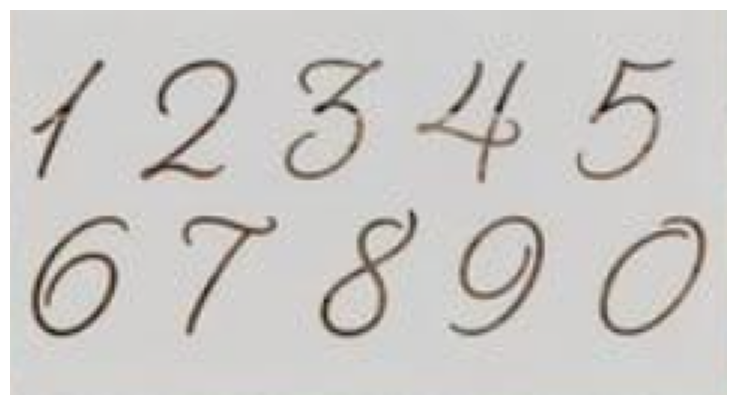

In [48]:

import cv2
import matplotlib.pyplot as plt

image = cv2.imread("Screenshot 2026-11-26 130126.png")

plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


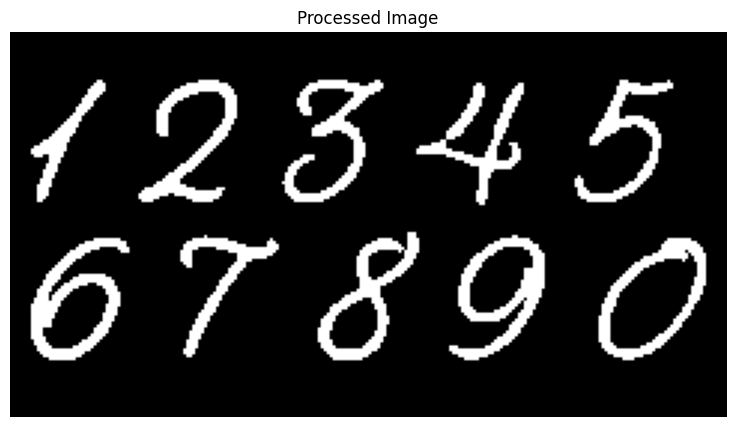

In [49]:

# Display the image after preprocessing

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

blur = cv2.GaussianBlur(gray, (5, 5), 0)

_, thresh = cv2.threshold(
    blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

plt.figure(figsize=(10, 5))
plt.imshow(thresh, cmap="gray")
plt.title("Processed Image")
plt.axis("off")
plt.show()


In [50]:
model.save("handwritten_recognition_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [52]:
files.download("handwritten_recognition_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>